# Notebook 05 · Noisy audio test

How much worse does "who spoke when" get when the audio is noisy? Two tests on the **reproduced baseline** (pyannote 2.1), scored exactly like Notebook 02:

| Part | Test | What it shows |
|---|---|---|
| 1 | **Real far-field audio:** the same 16 test meetings recorded by **one table microphone** (AMI *Single Distant Microphone*, `Array1-01`) instead of headsets | Real room noise, echo and distance |
| 2 | **Controlled noise:** headset audio of 4 test meetings with **pink noise** (fan or hum) and **babble** (other people talking) added at 20, 10 and 5 dB SNR | How the error grows as noise gets louder |

**Reference point for Part 1:** Workbook 1 cites pyannote 2.1 at **27.1% DER on AMI far-field** ([1], Bredin 2023). Check the exact row in Table 1 of the paper before quoting it.

**How to run:** kernel **Python (pyannote 2.1)** (Notebook 01 creates it) on the GPU pod. Time: Part 1 about 35 min (like Notebook 02); Part 2 about 45 min. Every answer is saved, so set `RESUME_RUN_ID` to continue.

The same noise method is in `src/demo/noise.py`, which the live demo uses to show a deliberately bad input.

## Settings

In [2]:
import os
from getpass import getpass
os.environ["HF_TOKEN"] = getpass("Token: ")

Token:  ········


In [3]:
import os
import sys
import json
import time
import wave
import random
import logging
import urllib.request
from pathlib import Path
from datetime import datetime, timezone
from getpass import getpass

import numpy as np


WORK         = Path("/workspace")
SETUP        = WORK / "AMI-diarization-setup"
MANIFEST     = WORK / "data_processed" / "prepared" / "manifest_all.csv"
WAREHOUSE    = WORK / "warehouse" / "ami.duckdb"
SDM_ROOT     = SETUP / "pyannote" / "amicorpus"             # same folder as the headset audio (database.yml); Notebook 03a downloads all splits here
NOISY_ROOT   = WORK / "data_processed" / "noisy"            # audio with added noise
BASELINE_RUN = WORK / "results" / "pyannote21_baseline" / "test" / "20261106_085354"   # Notebook 02 (headset)


# 1. Right environment?

print("Python:", sys.version.split()[0], "|", sys.executable)
if "envs/pyannote21" not in sys.executable:
    raise RuntimeError("Wrong kernel! Top-right: choose 'Python (pyannote 2.1)'.")


# 2. Same data and scoring rules as Notebook 02

SPLIT         = "test"
REFERENCE_SET = "only_words"
COLLAR        = 0.0
SKIP_OVERLAP  = False
PIPELINE_NAME = "pyannote/speaker-diarization@2.1"
SEED          = 42


# 3. Part 1: far-field audio

AMI_MIRROR      = "https://groups.inf.ed.ac.uk/ami/AMICorpusMirror/amicorpus"
SDM_CHANNEL     = "Array1-01"
PUBLISHED_SDM   = 27.1        # pyannote 2.1, AMI far-field, as cited in Workbook 1 [1] - verify in Table 1


# 4. Part 2: controlled noise (fixed before any result)

NOISE_MEETINGS  = ["IS1009a", "ES2004a", "TS3003a", "EN2002a"]   # one meeting from each test series
NOISE_TYPES     = ["pink", "babble"]
SNRS_DB         = [20, 10, 5]
BABBLE_VOICES   = 4


# 5. Run ID, output folder, token

RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S")
RESUME_RUN_ID = "20261106_112232"
if RESUME_RUN_ID:
    RUN_ID = RESUME_RUN_ID
OUT = WORK / "results" / "noise_test" / SPLIT / RUN_ID
for folder in [OUT / "figures", SDM_ROOT, NOISY_ROOT]:
    folder.mkdir(parents=True, exist_ok=True)

HF_TOKEN = os.environ.get("HF_TOKEN") or getpass("Paste your Hugging Face token: ")
os.environ["HF_TOKEN"] = HF_TOKEN

random.seed(SEED)
np.random.seed(SEED)
print("Run ID:", RUN_ID, "| results go to:", OUT)

Python: 3.9.23 | /workspace/envs/pyannote21/bin/python
Run ID: 20261106_112232 | results go to: /workspace/results/noise_test/test/20261106_112232


In [4]:
import torch

_original_stft = torch.stft

def _stft_on_cpu(input, *args, **kwargs):
    """Run the FFT on the CPU: the CUDA 11.7 cuFFT in this PyTorch fails on RTX 40-series GPUs.
    The result goes back to the original device, so the rest of the pipeline stays on the GPU."""
    if not input.is_cuda:
        return _original_stft(input, *args, **kwargs)
    to_cpu = lambda v: v.cpu() if torch.is_tensor(v) else v
    result = _original_stft(input.cpu(), *[to_cpu(a) for a in args], **{k: to_cpu(v) for k, v in kwargs.items()})
    return result.to(input.device)

torch.stft = _stft_on_cpu

# check that the patched version works on this GPU
x = torch.randn(1, 16000, device="cuda")
window = torch.hann_window(400, device="cuda")
out = torch.stft(x, 400, 160, 400, window, True, "constant", False, True, return_complex=True)
print("patched torch.stft works:", tuple(out.shape), out.device)


/workspace/envs/pyannote21/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


patched torch.stft works: (1, 201, 101) cuda:0


## Load the pipeline and the reference
Same pipeline, settings checks and reference files as Notebook 02.

In [5]:
import warnings
import pandas as pd
import matplotlib.pyplot as plt
import torch
import huggingface_hub.constants
import huggingface_hub.file_download
from pyannote.audio import Pipeline
from pyannote.core import Annotation
from pyannote.database.util import load_rttm, load_uem
from pyannote.metrics.diarization import DiarizationErrorRate

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
huggingface_hub.constants.HF_HUB_ENABLE_HF_TRANSFER = False
huggingface_hub.file_download.HF_HUB_ENABLE_HF_TRANSFER = False
torch.manual_seed(SEED)


# 1. Pipeline, on the GPU, scored with the rules it was tuned for

pipeline = Pipeline.from_pretrained(PIPELINE_NAME, use_auth_token=HF_TOKEN)
assert "cuda" in str(pipeline._segmentation.device), "Segmentation model is not on the GPU!"
assert pipeline.der_variant == {"collar": COLLAR, "skip_overlap": SKIP_OVERLAP}, pipeline.der_variant
GPU_NAME = torch.cuda.get_device_name(0)


# 2. Meetings, reference speakers, scored regions

meetings   = (SETUP / "lists" / f"{SPLIT}.meetings.txt").read_text().split()
references = {m: load_rttm(SETUP / REFERENCE_SET / "rttms" / SPLIT / f"{m}.rttm")[m] for m in meetings}
uems       = {m: load_uem(SETUP / "uems" / SPLIT / f"{m}.uem")[m] for m in meetings}
manifest   = pd.read_csv(MANIFEST).set_index("meeting")
headset_audio = {m: WORK / manifest.loc[m, "audio_path"] for m in manifest.index}

print(f"{len(meetings)} test meetings | GPU {GPU_NAME}")

torchvision is not available - cannot save figures
/workspace/envs/pyannote21/lib/python3.9/site-packages/pyannote/audio/core/model.py:426: UserWarning: Model was trained with pyannote.audio 0.0.1, yours is 2.1.1. Bad things will probably happen unless you update pyannote.audio to 0.x.
  warnings.warn(


16 test meetings | GPU NVIDIA GeForce RTX 4090


In [6]:
def read_wav(path):
    """16-bit PCM WAV -> float32 mono in [-1, 1], sample rate."""

    with wave.open(str(path), "rb") as w:
        rate, channels, width = w.getframerate(), w.getnchannels(), w.getsampwidth()
        assert width == 2, f"{path}: expected 16-bit audio"
        samples = np.frombuffer(w.readframes(w.getnframes()), dtype=np.int16)
    if channels > 1:
        samples = samples.reshape(-1, channels)[:, 0]
    return samples.astype(np.float32) / 32768.0, rate


def write_wav(path, audio, rate):

    temporary = Path(str(path) + ".part")
    with wave.open(str(temporary), "wb") as w:
        w.setnchannels(1)
        w.setsampwidth(2)
        w.setframerate(rate)
        w.writeframes((np.clip(audio, -1, 1) * 32767).astype(np.int16).tobytes())
    temporary.replace(path)


def diarize_and_score(meeting, audio_path, rttm_file, metric=None):
    """Run pyannote 2.1 on one audio file (or load its saved answer) and score it like Notebook 02."""

    if rttm_file.exists():
        hypothesis, seconds = load_rttm(rttm_file).get(meeting, Annotation(uri=meeting)), None
    else:
        start = time.perf_counter()
        hypothesis = pipeline({"uri": meeting, "audio": str(audio_path)})
        seconds = time.perf_counter() - start
        rttm_file.parent.mkdir(parents=True, exist_ok=True)
        temporary = rttm_file.with_name(rttm_file.name + ".part")
        with open(temporary, "w") as out:
            hypothesis.write_rttm(out)
        temporary.replace(rttm_file)

    reference, uem = references[meeting], uems[meeting]
    metric = metric or DiarizationErrorRate(collar=COLLAR, skip_overlap=SKIP_OVERLAP)
    d = metric(reference, hypothesis, uem=uem, detailed=True)
    overlap_region = reference.get_timeline().get_overlap().crop(uem)
    ov = DiarizationErrorRate(collar=COLLAR, skip_overlap=SKIP_OVERLAP)(reference, hypothesis, uem=overlap_region)
    return {
        "meeting": meeting,
        "DER_%": 100 * d["diarization error rate"],
        "missed_%": 100 * d["missed detection"] / d["total"],
        "false_alarm_%": 100 * d["false alarm"] / d["total"],
        "confusion_%": 100 * d["confusion"] / d["total"],
        "DER_overlap_%": 100 * ov,
        "predicted_speakers": len(hypothesis.labels()),
        "reference_speakers": len(reference.labels()),
        "processing_s": seconds,
    }

## Part 1 · Real far-field audio (AMI single distant microphone)
### Download
Downloads `Array1-01` for the 16 test meetings (about 1 GB). Complete files are skipped. Each file is checked to be 16 kHz, mono, 16-bit, and the same length as the headset recording (± 1 s).

In [7]:
def sdm_path(meeting):
    return SDM_ROOT / meeting / "audio" / f"{meeting}.{SDM_CHANNEL}.wav"


def download(url, destination, retries=3):

    if destination.exists():
        return "skipped"
    destination.parent.mkdir(parents=True, exist_ok=True)
    temporary = destination.with_name(destination.name + ".part")
    for attempt in range(1, retries + 1):
        try:
            with urllib.request.urlopen(url, timeout=60) as response, open(temporary, "wb") as out:
                expected = int(response.headers.get("Content-Length", 0))
                while chunk := response.read(1 << 20):
                    out.write(chunk)
            if expected and temporary.stat().st_size != expected:
                raise IOError(f"size {temporary.stat().st_size} != {expected}")
            temporary.replace(destination)
            return "downloaded"
        except Exception as error:
            logging.warning(f"{destination.name}: attempt {attempt} failed: {error}")
            time.sleep(5 * attempt)
    raise RuntimeError(f"Could not download {url}")


sdm_checks = []
for meeting in meetings:
    status = download(f"{AMI_MIRROR}/{meeting}/audio/{meeting}.{SDM_CHANNEL}.wav", sdm_path(meeting))
    with wave.open(str(sdm_path(meeting)), "rb") as w:
        fmt = (w.getframerate(), w.getnchannels(), w.getsampwidth())
        length = w.getnframes() / w.getframerate()
    with wave.open(str(headset_audio[meeting]), "rb") as w:
        headset_length = w.getnframes() / w.getframerate()
    sdm_checks.append({"meeting": meeting, "status": status, "format_ok": fmt == (16000, 1, 2),
                       "length_s": round(length, 1), "headset_length_s": round(headset_length, 1),
                       "length_ok": abs(length - headset_length) <= 1.0})

sdm_checks = pd.DataFrame(sdm_checks)
sdm_checks.to_csv(OUT / "sdm_audio_checks.csv", index=False)
print(sdm_checks.to_string(index=False))
assert sdm_checks["format_ok"].all(), "Some far-field files are not 16 kHz mono 16-bit - see the table."
if not sdm_checks["length_ok"].all():
    print("NOTE: some far-field files differ in length from the headset files - scoring still uses the official UEM.")

meeting  status  format_ok  length_s  headset_length_s  length_ok
IS1009a skipped       True     839.0             838.8       True
IS1009b skipped       True    2052.4            2052.3       True
IS1009c skipped       True    1820.8            1820.8       True
IS1009d skipped       True    1944.7            1944.5       True
ES2004a skipped       True    1049.4            1049.4       True
ES2004b skipped       True    2345.5            2345.5       True
ES2004c skipped       True    2334.4            2334.4       True
ES2004d skipped       True    2222.3            2222.3       True
TS3003a skipped       True    1505.6            1505.6       True
TS3003b skipped       True    2210.3            2210.3       True
TS3003c skipped       True    2570.0            2570.0       True
TS3003d skipped       True    2618.2            2618.2       True
EN2002a skipped       True    2142.7            2142.7       True
EN2002b skipped       True    1786.8            1786.8       True
EN2002c sk

### Diarize and score the far-field audio

In [8]:
metric_sdm = DiarizationErrorRate(collar=COLLAR, skip_overlap=SKIP_OVERLAP)
sdm_rows = []
for i, meeting in enumerate(meetings, start=1):
    row = diarize_and_score(meeting, sdm_path(meeting), OUT / "rttm_sdm" / f"{meeting}.rttm", metric_sdm)
    sdm_rows.append(row)
    print(f"[{i:2d}/{len(meetings)}] {meeting}: far-field DER {row['DER_%']:5.2f}% | overlap {row['DER_overlap_%']:5.1f}% "
          f"| speakers {row['predicted_speakers']} vs {row['reference_speakers']}")

sdm = pd.DataFrame(sdm_rows)
report = metric_sdm.report(display=False).loc["TOTAL"]
speech = report[("total", "")]
sdm_pooled = {"DER_%": abs(metric_sdm) * 100,
              "missed_%": 100 * report[("missed detection", "")] / speech,
              "false_alarm_%": 100 * report[("false alarm", "")] / speech,
              "confusion_%": 100 * report[("confusion", "")] / speech}

headset = pd.read_csv(BASELINE_RUN / "per_meeting_results.csv").set_index("meeting")
headset_summary = json.loads((BASELINE_RUN / "summary.json").read_text())
both = sdm.set_index("meeting")[["DER_%", "DER_overlap_%", "predicted_speakers"]].join(
    headset[["DER_%", "DER_overlap_%", "predicted_speakers"]], lsuffix="_farfield", rsuffix="_headset")
both["DER_change_points"] = both["DER_%_farfield"] - both["DER_%_headset"]
sdm.to_csv(OUT / "per_meeting_farfield.csv", index=False)
both.to_csv(OUT / "farfield_vs_headset.csv")

print(f"\nPooled DER  headset (Notebook 02): {headset_summary['der_%']:.2f}%")
print(f"Pooled DER  far-field (this run) : {sdm_pooled['DER_%']:.2f}%   (published far-field: {PUBLISHED_SDM}%)")
print("Parts (far-field):", {k: round(v, 2) for k, v in sdm_pooled.items()})
print(f"Far-field is worse in {(both['DER_change_points'] > 0).sum()} of {len(both)} meetings.")

[ 1/16] IS1009a: far-field DER 25.16% | overlap  41.3% | speakers 5 vs 4
[ 2/16] IS1009b: far-field DER 14.62% | overlap  39.8% | speakers 5 vs 4
[ 3/16] IS1009c: far-field DER 10.57% | overlap  40.3% | speakers 5 vs 4
[ 4/16] IS1009d: far-field DER 23.23% | overlap  51.3% | speakers 6 vs 4
[ 5/16] ES2004a: far-field DER 29.09% | overlap  48.5% | speakers 5 vs 4
[ 6/16] ES2004b: far-field DER 18.68% | overlap  44.3% | speakers 6 vs 4
[ 7/16] ES2004c: far-field DER 17.38% | overlap  38.1% | speakers 5 vs 4
[ 8/16] ES2004d: far-field DER 37.34% | overlap  57.4% | speakers 6 vs 4
[ 9/16] TS3003a: far-field DER 40.47% | overlap  63.8% | speakers 3 vs 4
[10/16] TS3003b: far-field DER 20.42% | overlap  46.8% | speakers 5 vs 4
[11/16] TS3003c: far-field DER 23.83% | overlap  46.5% | speakers 5 vs 4
[12/16] TS3003d: far-field DER 36.40% | overlap  50.6% | speakers 6 vs 4
[13/16] EN2002a: far-field DER 32.23% | overlap  42.3% | speakers 5 vs 4
[14/16] EN2002b: far-field DER 31.89% | overlap  43

## Part 2 · Controlled noise
Headset audio of 4 test meetings (one per meeting series) with noise added at a fixed SNR over the whole recording, the same method as `src/demo/noise.py`:
* **pink**: steady noise with more low-frequency energy, like a fan, air conditioning or hum.
* **babble**: 4 overlapping stretches of **train-split** meetings, like people talking nearby. Train audio is used so that no test speaker appears in the noise.

Each noisy file is saved once and re-used. The noise seed is fixed.

In [9]:
def pink_noise(n_samples, rng):
    spectrum = rng.standard_normal(n_samples // 2 + 1) + 1j * rng.standard_normal(n_samples // 2 + 1)
    frequencies = np.arange(len(spectrum), dtype=float)
    frequencies[0] = 1.0
    return np.fft.irfft(spectrum / np.sqrt(frequencies), n=n_samples).astype(np.float32)


def babble_noise(n_samples, rng):
    """Sum of BABBLE_VOICES random stretches from random TRAIN meetings."""

    train = manifest[manifest["split"] == "train"].index.tolist()
    noise = np.zeros(n_samples, dtype=np.float32)
    for meeting in rng.choice(train, size=BABBLE_VOICES, replace=False):
        source, _ = read_wav(headset_audio[meeting])
        start = int(rng.integers(0, max(1, len(source) - 1)))
        noise += np.resize(np.roll(source, -start), n_samples)
    return noise


def add_noise(audio, snr_db, kind, seed):
    rng = np.random.default_rng(seed)
    noise = pink_noise(len(audio), rng) if kind == "pink" else babble_noise(len(audio), rng)
    scale = np.sqrt(np.mean(audio ** 2) / (np.mean(noise ** 2) * 10 ** (snr_db / 10)))
    return np.clip(audio + scale * noise, -1, 1).astype(np.float32), float(10 * np.log10(np.mean(audio ** 2) / np.mean((scale * noise) ** 2)))


noise_rows = []
for kind in NOISE_TYPES:
    for snr in SNRS_DB:
        for meeting in NOISE_MEETINGS:
            noisy_file = NOISY_ROOT / f"{kind}_{snr}dB" / f"{meeting}.wav"
            measured = None
            if not noisy_file.exists():
                clean, rate = read_wav(headset_audio[meeting])
                noisy, measured = add_noise(clean, snr, kind, seed=SEED + snr)
                noisy_file.parent.mkdir(parents=True, exist_ok=True)
                write_wav(noisy_file, noisy, rate)
            row = diarize_and_score(meeting, noisy_file, OUT / "rttm_noise" / f"{kind}_{snr}dB" / f"{meeting}.rttm")
            noise_rows.append({"noise": kind, "snr_db": snr, "snr_db_measured": measured, **row})
            print(f"{kind:6s} {snr:2d} dB  {meeting}: DER {row['DER_%']:5.2f}% | speakers {row['predicted_speakers']} vs {row['reference_speakers']}")

noise = pd.DataFrame(noise_rows)
clean_rows = headset.loc[NOISE_MEETINGS].reset_index()[["meeting", "DER_%", "missed_%", "false_alarm_%", "confusion_%", "DER_overlap_%"]]
clean_rows = clean_rows.assign(noise="none (headset)", snr_db=np.inf)
noise_all = pd.concat([clean_rows, noise], ignore_index=True)
noise_all.to_csv(OUT / "per_meeting_noise.csv", index=False)


# Pooled per condition: weighted by reference speech, like DER itself

speech_min = headset.loc[NOISE_MEETINGS, "reference_speech_min"]
noise_all["speech_min"] = noise_all["meeting"].map(speech_min)
summary_noise = (noise_all.assign(err=lambda t: t["DER_%"] * t["speech_min"])
                          .groupby(["noise", "snr_db"])
                          .apply(lambda g: pd.Series({"DER_%": g["err"].sum() / g["speech_min"].sum(),
                                                      "missed_%": np.average(g["missed_%"], weights=g["speech_min"]),
                                                      "false_alarm_%": np.average(g["false_alarm_%"], weights=g["speech_min"]),
                                                      "confusion_%": np.average(g["confusion_%"], weights=g["speech_min"])}))
                          .reset_index())
summary_noise.to_csv(OUT / "noise_summary.csv", index=False)
print("\n", summary_noise.round(2).to_string(index=False))

pink   20 dB  IS1009a: DER 20.44% | speakers 4 vs 4
pink   20 dB  ES2004a: DER 21.00% | speakers 5 vs 4
pink   20 dB  TS3003a: DER 19.90% | speakers 2 vs 4
pink   20 dB  EN2002a: DER 29.16% | speakers 8 vs 4
pink   10 dB  IS1009a: DER 23.06% | speakers 6 vs 4
pink   10 dB  ES2004a: DER 23.68% | speakers 5 vs 4
pink   10 dB  TS3003a: DER 21.47% | speakers 2 vs 4
pink   10 dB  EN2002a: DER 42.57% | speakers 5 vs 4
pink    5 dB  IS1009a: DER 23.74% | speakers 5 vs 4
pink    5 dB  ES2004a: DER 52.71% | speakers 5 vs 4
pink    5 dB  TS3003a: DER 23.17% | speakers 3 vs 4
pink    5 dB  EN2002a: DER 41.35% | speakers 5 vs 4
babble 20 dB  IS1009a: DER 40.68% | speakers 4 vs 4
babble 20 dB  ES2004a: DER 54.81% | speakers 5 vs 4
babble 20 dB  TS3003a: DER 28.63% | speakers 2 vs 4
babble 20 dB  EN2002a: DER 47.58% | speakers 7 vs 4
babble 10 dB  IS1009a: DER 92.51% | speakers 4 vs 4
babble 10 dB  ES2004a: DER 109.10% | speakers 8 vs 4
babble 10 dB  TS3003a: DER 124.65% | speakers 6 vs 4
babble 10 

## Figure: error as noise gets louder

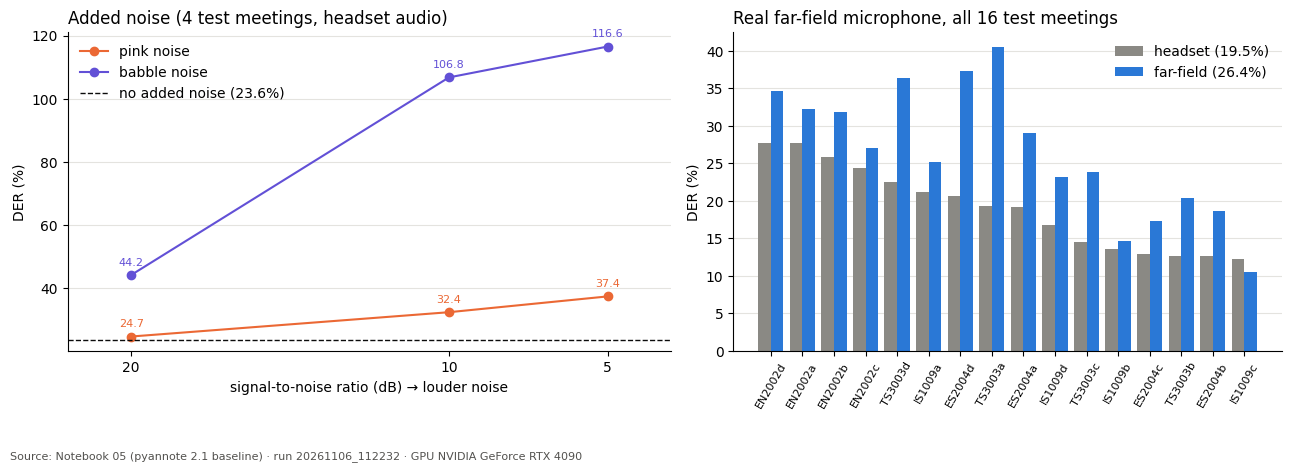

Saved: /workspace/results/noise_test/test/20261106_112232/figures/noise_test.png


In [10]:
INK, NEUTRAL = "#0b0b0b", "#52514e"
COLORS = {"pink": "#eb6834", "babble": "#6250d6"}
clean_der = summary_noise.loc[summary_noise["noise"] == "none (headset)", "DER_%"].iloc[0]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), gridspec_kw={"width_ratios": [1.1, 1]})

# Left: DER vs SNR
ax = axes[0]
for kind in NOISE_TYPES:
    part = summary_noise[summary_noise["noise"] == kind].sort_values("snr_db", ascending=False)
    ax.plot(part["snr_db"], part["DER_%"], marker="o", color=COLORS[kind], label=f"{kind} noise")
    for _, row in part.iterrows():
        ax.annotate(f"{row['DER_%']:.1f}", (row["snr_db"], row["DER_%"]), textcoords="offset points", xytext=(0, 7),
                    ha="center", fontsize=8, color=COLORS[kind])
ax.axhline(clean_der, color=INK, linestyle="--", linewidth=1, label=f"no added noise ({clean_der:.1f}%)")
ax.set_xlim(max(SNRS_DB) + 2, min(SNRS_DB) - 2)
ax.set_xticks(SNRS_DB)
ax.set_xlabel("signal-to-noise ratio (dB) → louder noise")
ax.set_ylabel("DER (%)")
ax.set_title(f"Added noise ({len(NOISE_MEETINGS)} test meetings, headset audio)", loc="left")
ax.legend(frameon=False)

# Right: headset vs far-field per meeting
ax = axes[1]
order = both.sort_values("DER_%_headset", ascending=False).index
x = np.arange(len(order))
ax.bar(x - 0.2, both.loc[order, "DER_%_headset"], width=0.4, color="#8a8984", label=f"headset ({headset_summary['der_%']:.1f}%)")
ax.bar(x + 0.2, both.loc[order, "DER_%_farfield"], width=0.4, color="#2a78d6", label=f"far-field ({sdm_pooled['DER_%']:.1f}%)")
ax.set_xticks(x)
ax.set_xticklabels(order, rotation=60, fontsize=8)
ax.set_ylabel("DER (%)")
ax.set_title("Real far-field microphone, all 16 test meetings", loc="left")
ax.legend(frameon=False)

for a in axes:
    a.spines[["top", "right"]].set_visible(False)
    a.grid(axis="y", color="#e4e3df", linewidth=0.8)
    a.set_axisbelow(True)
fig.text(0.01, -0.08, f"Source: Notebook 05 (pyannote 2.1 baseline) · run {RUN_ID} · GPU {GPU_NAME}", fontsize=8, color=NEUTRAL)
plt.tight_layout()
figure_file = OUT / "figures" / "noise_test.png"
plt.savefig(figure_file, dpi=150, bbox_inches="tight")
plt.show()
print("Saved:", figure_file)

## Save the summary and the warehouse table

In [11]:
import duckdb

summary = {
    "run_id": RUN_ID, "pipeline": PIPELINE_NAME, "gpu": GPU_NAME, "split": SPLIT,
    "farfield": {"channel": SDM_CHANNEL, "meetings": len(meetings), **{k: round(v, 2) for k, v in sdm_pooled.items()},
                 "published_der_%": PUBLISHED_SDM, "headset_der_%": headset_summary["der_%"],
                 "worse_than_headset_meetings": int((both["DER_change_points"] > 0).sum())},
    "added_noise": {"meetings": NOISE_MEETINGS, "types": NOISE_TYPES, "snrs_db": SNRS_DB, "babble_voices": BABBLE_VOICES,
                    "results": summary_noise.replace([np.inf], "clean").round(2).to_dict(orient="records")},
    "scoring": {"collar": COLLAR, "skip_overlap": SKIP_OVERLAP, "reference_set": REFERENCE_SET},
    "seed": SEED,
}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, default=float))

table = pd.concat([
    sdm.assign(condition=f"farfield_{SDM_CHANNEL}", snr_db=np.nan),
    noise.assign(condition=lambda t: t["noise"] + "_" + t["snr_db"].astype(str) + "dB"),
], ignore_index=True).assign(model="pyannote2.1_baseline", run_id=RUN_ID)

with duckdb.connect(str(WAREHOUSE)) as con:
    con.register("incoming", table)
    con.execute("CREATE TABLE IF NOT EXISTS noise_results AS SELECT * FROM incoming WHERE 1 = 0")
    con.execute("DELETE FROM noise_results WHERE run_id = ?", [RUN_ID])
    con.execute("INSERT INTO noise_results BY NAME SELECT * FROM incoming")
    con.unregister("incoming")
    print(con.execute("SELECT condition, COUNT(*) AS meetings, ROUND(AVG(\"DER_%\"), 2) AS mean_DER FROM noise_results "
                      "WHERE run_id = ? GROUP BY condition ORDER BY condition", [RUN_ID]).df().to_string(index=False))

print("\nSaved:", OUT)

         condition  meetings  mean_DER
       babble_10dB         4    107.21
       babble_20dB         4     42.92
        babble_5dB         4    119.30
farfield_Array1-01        16     26.44
         pink_10dB         4     27.70
         pink_20dB         4     22.62
          pink_5dB         4     35.24

Saved: /workspace/results/noise_test/test/20261106_112232


## Findings
Fill in after running.

* **Far-field vs headset (all 16 meetings):** …
* **Compared with the published far-field number (27.1%):** …
* **Added noise: at what SNR does DER pass 25%? Which noise is worse?** …
* **Which part grows most (missed speech, false alarm, confusion)?** …
* **When the system should not be used:** …